[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/notebooks/06_spatial_frequency_admin.ipynb)


# บทที่ 06 — ความถี่เชิงพื้นที่ สถิติเชิงพื้นที่ และการสรุปรายตำบล/อำเภอ/จังหวัด

บทสุดท้ายรวมทุกอย่างเป็นแผนที่ที่ผู้ใช้งานจริง (อปท., ปภ., นักวางแผน) อ่านได้: **พื้นที่ไหนพายุผ่านบ่อย ก่อตัวบ่อย หรือมีลูกเห็บบ่อย** แล้วทดสอบว่ารูปแบบที่เห็นเป็นกลุ่มก้อนจริง (spatial autocorrelation) หรือเกิดโดยบังเอิญ และเทียบกับรายงานความเสียหาย

### วัตถุประสงค์การเรียนรู้
1. สร้างแผนที่ความถี่ที่ปรับด้วยเวลาที่สังเกตได้ และแผนที่ความหนาแน่นเส้นทาง/จุดกำเนิด (KDE)
2. สรุปกริดเป็นหน่วยการปกครองด้วย zonal statistics (storm-hours, % พื้นที่ที่พายุกวาดผ่าน)
3. คำนวณ Global Moran's I และ Getis–Ord $G_i^*$ เพื่อหา hot/cold spot
4. เปรียบเทียบความถี่จากเรดาร์กับรายงานความเสียหาย และอธิบาย exposure bias
5. ส่งออกผลเป็น GeoPackage/GeoTIFF และทำแผนที่สังเคราะห์มาตรฐานวารสาร

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 8 core


In [2]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats, ndimage
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M, geo as G, data as D, analysis as A, track_tools as tt
s = load_settings()
M.setup_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
DEM = G.load_dem(s)                                   # (array, extent) — สร้างจาก Copernicus ครั้งแรกถ้ายังไม่มี
idx = D.day_index()
KEY_DAYS = list(idx.loc[idx["in_repo"], "day"]) if len(idx) else [pd.Timestamp("2024-05-03")]
KEY = KEY_DAYS[0]                                     # วันหลักที่มีกริดใน repo (เปลี่ยนเป็นวันอื่นได้ จะดาวน์โหลดจาก Zenodo)
print("วันหลักใน repo:", [f"{d:%d %b}" for d in KEY_DAYS], "| ใช้วัน:", f"{KEY:%d %b %Y}")

import geopandas as gpd
from scipy.stats import gaussian_kde
with xr.open_dataset(repo_path("data", "derived", "monthly_summary_1km.nc")) as ms:
    MS = {k: ms[k].values for k in ms.data_vars}; ATTR = dict(ms.attrs)
_, meta = D.load_cappi(KEY)
TAG = "15min"
T = A.month_tracks(TAG, s["tracking"]["min_life_min"])
N_OBS = int(np.nanmax(MS["n_obs_total"]))
print(f"ข้อมูล {len(ATTR['days'].split(','))} วัน, {N_OBS} volume (= {N_OBS * 0.25:.0f} ชั่วโมงที่สังเกต) | เส้นทาง {len(T)}")

วันหลักใน repo: ['03 May', '05 May', '06 May', '22 May'] | ใช้วัน: 03 May 2024
ข้อมูล 31 วัน, 2962 volume (= 740 ชั่วโมงที่สังเกต) | เส้นทาง 2325


## 1. แผนที่ความถี่ 4 แบบ

| แผนที่ | สูตร | ความหมาย |
|---|---|---|
| ความถี่ echo ≥ 35 dBZ | $100\,N_{Z\ge35}/N_{\text{obs}}$ (%) | ฝนฟ้าคะนองปกคลุมบ่อยแค่ไหน |
| storm-hours | $0.25\,N_{Z\ge35}$ (ชั่วโมง) | ระยะเวลารวมที่มีพายุเหนือ pixel |
| ความหนาแน่นเส้นทาง | จำนวน footprint ที่กวาดผ่าน | พายุ "ลูก" ต่าง ๆ ผ่านบ่อยแค่ไหน |
| จุดกำเนิด (KDE) | $\hat f(\mathbf{x}) = \frac{1}{n}\sum_i K_h(\mathbf{x}-\mathbf{x}_i)$ | พายุเริ่มก่อตัวที่ไหนบ่อย |

storm-hours กับความหนาแน่นเส้นทางต่างกัน: พายุลูกเดียวที่นิ่งนาน 3 ชั่วโมงให้ storm-hours สูงแต่ความหนาแน่นเส้นทาง = 1

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb06_frequency_maps.png / .pdf


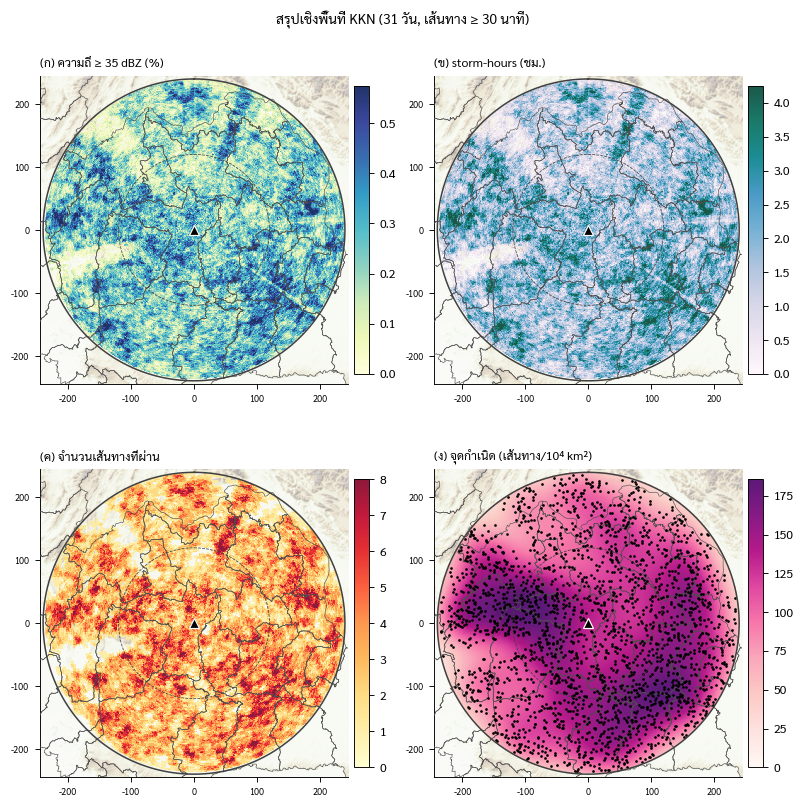

In [3]:
C = A.month_cells(TAG)
st0 = C.sort_values("time").groupby("uid").first().loc[T["uid"]]
xy = np.vstack([st0["cx"] / 1e3, st0["cy"] / 1e3])
X, Y = np.meshgrid(meta["x"] / 1e3, meta["y"] / 1e3)
kde = gaussian_kde(xy, bw_method=0.25) if xy.shape[1] >= 5 else None
KDE = (kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape) * len(T) * 1e4) if kde else np.full(X.shape, np.nan)  # ต่อ 100×100 km²
KDE = np.where(meta["coverage"], KDE, np.nan)
SH = MS["freq_ge35_pct"] / 100 * N_OBS * 0.25
panels = [(MS["freq_ge35_pct"], "(ก) ความถี่ ≥ 35 dBZ (%)", "YlGnBu"), (SH, "(ข) storm-hours (ชม.)", "PuBuGn"),
          (MS[f"track_density_{TAG}"], "(ค) จำนวนเส้นทางที่ผ่าน", "YlOrRd"), (KDE, "(ง) จุดกำเนิด (เส้นทาง/10⁴ km²)", "RdPu")]
fig, axs = plt.subplots(2, 2, figsize=(7.2, 7.4), layout="constrained")
for ax, (g, ttl, cm) in zip(axs.flat, panels):
    M.add_hillshade(ax, *DEM, alpha=0.45)
    gg = np.where(g > 0, g, np.nan)
    im = A.show_grid(ax, gg, meta, cmap=cm, vmin=0, vmax=np.nanpercentile(gg, 99) if np.isfinite(gg).any() else 1, alpha=0.9, zorder=3)
    if "จุดกำเนิด" in ttl:
        ax.plot(xy[0], xy[1], ".", ms=1.5, color="k", zorder=6)
    M.plot_km(G.load_admin("province", s), ax, facecolor="none", edgecolor="0.3", lw=0.4, zorder=5)
    M.add_range_rings(ax, s, rings_km=[120, 240], label=False, name=False)
    ax.set_xlim(-245, 245); ax.set_ylim(-245, 245); ax.set_aspect("equal"); ax.tick_params(labelsize=6)
    ax.set_title(ttl, loc="left", fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
fig.suptitle(f"สรุปเชิงพื้นที่ KKN ({len(ATTR['days'].split(','))} วัน, เส้นทาง ≥ {s['tracking']['min_life_min']} นาที)", fontsize=9)
M.savefig(fig, "nb06_frequency_maps")
plt.show()

## 2. สรุปเป็นหน่วยการปกครอง

ใช้เฉพาะหน่วยที่อยู่ในรัศมี 240 km เกิน 90% ของพื้นที่ (ขอบรัศมีมีข้อมูลไม่ครบ) ตัวชี้วัด:
- `freq35_mean` ความถี่เฉลี่ย (%)
- `storm_hours_mean` storm-hours เฉลี่ยต่อ pixel
- `swept_pct` ร้อยละของพื้นที่ที่มีเส้นทางกวาดผ่านอย่างน้อย 1 ครั้ง
- `n_tracks_max` จำนวนเส้นทางสูงสุดที่ผ่าน pixel ใดในหน่วยนั้น

In [4]:
def admin_summary(layer, id_col, name_cols):
    g = G.load_admin(layer, s)
    # บางรหัสมีหลาย polygon (เช่น เกาะ/ส่วนแยก) → รวมเป็นหนึ่งหน่วยต่อรหัส
    g = g.dissolve(by=id_col, as_index=False, aggfunc="first")
    disk = G.coverage_disk(s).geometry.iloc[0]
    g = g[g.geometry.intersection(disk).area / g.geometry.area >= 0.9].reset_index(drop=True)
    out = g[[id_col] + name_cols + ["geometry"]].copy()
    for col, grid, st in [("freq35_mean", MS["freq_ge35_pct"], "mean"), ("storm_hours_mean", SH, "mean"),
                          ("n_tracks_max", MS[f"track_density_{TAG}"], "max"),
                          ("swept_pct", 100 * (MS[f"track_density_{TAG}"] > 0), "mean"),
                          ("hail_count_max", MS["hail_col_count"], "max")]:
        z = A.zonal_by_polygon(grid, meta, g, id_col, stats=(st,))
        out[col] = out[id_col].map(z[st])
    return out

AMP = admin_summary("district", "amp_code", ["pro_th", "amp_th"])
TAM = admin_summary("subdistrict", "tam_code", ["pro_th", "amp_th", "tam_th"])
print(f"อำเภอ {len(AMP)} | ตำบล {len(TAM)}")
AMP.drop(columns="geometry").sort_values("storm_hours_mean", ascending=False).head(10).round(2)

อำเภอ 289 | ตำบล 2489


,amp_code,pro_th,amp_th,freq35_mean,storm_hours_mean,n_tracks_max,swept_pct,hail_count_max
213,4513,ร้อยเอ็ด,โพนทราย,0.48,3.54,11.0,100.0,8.0
56,3208,สุรินทร์,สนม,0.46,3.38,10.0,100.0,8.0
206,4506,ร้อยเอ็ด,พนมไพร,0.45,3.32,10.0,100.0,8.0
136,4018,ขอนแก่น,ชนบท,0.44,3.24,10.0,100.0,14.0
65,3302,ศรีสะเกษ,ยางชุมน้อย,0.42,3.09,7.0,100.0,6.0
67,3309,ศรีสะเกษ,ราษีไศล,0.41,3.04,9.0,100.0,6.0
219,4519,ร้อยเอ็ด,หนองฮี,0.40,2.97,9.0,100.0,5.0
69,3311,ศรีสะเกษ,บึงบูรพ์,0.39,2.90,8.0,100.0,4.0
55,3207,สุรินทร์,รัตนบุรี,0.39,2.90,12.0,100.0,6.0
58,3211,สุรินทร์,ลำดวน,0.39,2.88,11.0,100.0,3.0


In [5]:
PROV = AMP.drop(columns="geometry").groupby("pro_th")[["freq35_mean", "storm_hours_mean", "swept_pct"]].mean()
PROV.sort_values("storm_hours_mean", ascending=False).round(2)

,freq35_mean,storm_hours_mean,swept_pct
pro_th,,,
สุรินทร์,0.33,2.46,97.86
ร้อยเอ็ด,0.33,2.41,99.55
ศรีสะเกษ,0.32,2.36,98.99
อุบลราชธานี,0.31,2.28,92.67
พิษณุโลก,0.30,2.21,92.07
มุกดาหาร,0.30,2.20,98.28
ขอนแก่น,0.29,2.13,98.29
อำนาจเจริญ,0.28,2.09,99.29
ลพบุรี,0.28,2.07,85.66


## 3. สถิติเชิงพื้นที่ระดับอำเภอ

**Global Moran's I** (queen contiguity, row-standardized $W$):

$$I = \frac{n}{S_0}\frac{\sum_i\sum_j w_{ij}(x_i-\bar x)(x_j-\bar x)}{\sum_i (x_i-\bar x)^2}, \qquad E[I] = -\frac{1}{n-1}$$

$I > E[I]$ อย่างมีนัยสำคัญ = อำเภอที่มีค่าสูงอยู่ติดกันเป็นกลุ่ม p-value จากการสุ่มสลับค่า 999 ครั้ง

**Getis–Ord $G_i^*$** (รวมตัวเอง, น้ำหนักแบบ 0/1): ค่า z > 1.96 = hot spot, < −1.96 = cold spot (ระดับ 5% แบบไม่ปรับการทดสอบซ้ำ — ควรตีความอย่างระวัง)

In [6]:
var = "storm_hours_mean"
Ag = AMP.dropna(subset=[var]).reset_index(drop=True)
Wr = A.queen_weights(Ag)
I, pI, EI = A.morans_i(Ag[var].values, Wr)
print(f"Moran's I ({var}) = {I:.3f}  (E[I] = {EI:.3f}), p = {pI:.3f}, n = {len(Ag)} อำเภอ")
Ag["Gi_z"] = A.getis_ord_gi(Ag[var].values, A.binary_weights_self(Ag))
Ag["Gi_class"] = pd.cut(Ag["Gi_z"], [-np.inf, -2.58, -1.96, 1.96, 2.58, np.inf],
                        labels=["cold 99%", "cold 95%", "ไม่มีนัยสำคัญ", "hot 95%", "hot 99%"])
Ag["Gi_class"].value_counts().sort_index()

Moran's I (storm_hours_mean) = 0.526  (E[I] = -0.003), p = 0.001, n = 289 อำเภอ


,count
Gi_class,
cold 99%,22
cold 95%,16
ไม่มีนัยสำคัญ,214
hot 95%,15
hot 99%,22


## 4. เทียบกับรายงานความเสียหาย (บท 01)

In [7]:
REP = pd.read_csv(repo_path("data", "reports", "reports_may2024_clean.csv"), dtype={"amp_code": str})
days_used = [pd.Timestamp(d) for d in ATTR["days"].split(",")]
REP = REP[pd.to_datetime(REP["date"]).isin(days_used)]
Ag["amp_code"] = Ag["amp_code"].astype(str)
Ag["n_reports"] = Ag["amp_code"].map(REP.groupby("amp_code").size()).fillna(0).astype(int)
a, b = Ag.loc[Ag["n_reports"] > 0, var], Ag.loc[Ag["n_reports"] == 0, var]
print(f"อำเภอที่มีรายงาน n={len(a)} มัธยฐาน storm-hours {a.median():.2f} | ไม่มี n={len(b)} มัธยฐาน {b.median():.2f}")
if min(len(a), len(b)) >= 3:
    print(stats.mannwhitneyu(a, b, alternative="greater"), "| Cliff δ =", round(tt.cliffs_delta(a, b), 2))

อำเภอที่มีรายงาน n=52 มัธยฐาน storm-hours 1.78 | ไม่มี n=237 มัธยฐาน 1.86
MannwhitneyuResult(statistic=np.float64(5477.0), pvalue=np.float64(0.8954596296125183)) | Cliff δ = -0.11


**exposure bias:** อำเภอที่พายุผ่านบ่อยแต่ไม่มีรายงาน อาจเป็นพื้นที่ป่า/ภูเขาที่มีบ้านเรือนน้อย หรือพายุช่วงนั้นไม่แรงพอ ส่วนอำเภอที่มีรายงานแต่ storm-hours ต่ำ อาจโดนพายุลูกเดียวที่แรงมาก — ความถี่และความรุนแรงเป็นคนละมิติ

## 5. แผนที่สังเคราะห์ (มาตรฐานวารสาร)

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb06_admin_hotspots.png / .pdf


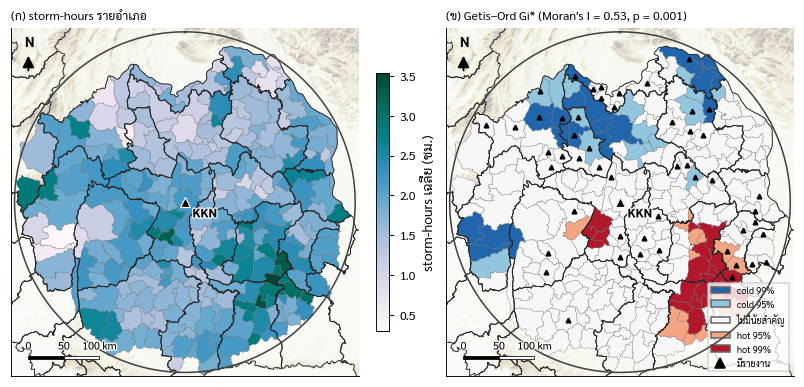

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 4.0), layout="constrained")
ax = axs[0]
M.add_hillshade(ax, *DEM, alpha=0.4)
M.plot_km(Ag, ax, column=var, cmap="PuBuGn", edgecolor="0.4", lw=0.2, zorder=3, legend=True,
          legend_kwds={"shrink": 0.6, "label": "storm-hours เฉลี่ย (ชม.)"})
ax.set_title("(ก) storm-hours รายอำเภอ", loc="left", fontsize=8)
ax = axs[1]
M.add_hillshade(ax, *DEM, alpha=0.4)
gcol = {"cold 99%": "#2166ac", "cold 95%": "#92c5de", "ไม่มีนัยสำคัญ": "#f7f7f7", "hot 95%": "#f4a582", "hot 99%": "#b2182b"}
for k, c in gcol.items():
    sub = Ag[Ag["Gi_class"] == k]
    if len(sub):
        M.plot_km(sub, ax, color=c, edgecolor="0.4", lw=0.2, zorder=3)
rep_amp = Ag[Ag["n_reports"] > 0]
if len(rep_amp):
    cen = rep_amp.geometry.representative_point()
    ax.plot(cen.x / 1e3, cen.y / 1e3, "k^", ms=3, zorder=6, label="มีรายงานความเสียหาย")
from matplotlib.patches import Patch
ax.legend([Patch(color=c, ec="0.4") for c in gcol.values()] + [plt.Line2D([], [], marker="^", color="k", ls="")],
          list(gcol) + ["มีรายงาน"], fontsize=6, loc="lower right", frameon=True)
ax.set_title(f"(ข) Getis–Ord Gi* (Moran's I = {I:.2f}, p = {pI:.3f})", loc="left", fontsize=8)
for ax in axs:
    M.plot_km(G.load_admin("province", s), ax, facecolor="none", edgecolor="0.15", lw=0.6, zorder=5)
    M.add_range_rings(ax, s, rings_km=[240], label=False)
    ax.set_xlim(-245, 245); ax.set_ylim(-245, 245); ax.set_aspect("equal")
    M.add_scalebar(ax); M.add_north_arrow(ax)
    ax.set_xticks([]); ax.set_yticks([])
M.savefig(fig, "nb06_admin_hotspots")
plt.show()

## 6. ส่งออกเพื่อใช้ใน QGIS

In [9]:
out = repo_path("figures", "gis"); out.mkdir(parents=True, exist_ok=True)
Ag.to_crs(4326).to_file(out / "nb06_amphoe_storm_summary.gpkg", driver="GPKG")
TAM.to_crs(4326).to_file(out / "nb06_tambon_storm_summary.gpkg", driver="GPKG")
from utils.data_io import save_geotiff
save_geotiff(str(out / "nb06_frequency_maps.tif"), [MS["freq_ge35_pct"], SH, MS[f"track_density_{TAG}"], KDE], meta,
             band_names=["freq_ge35_pct", "storm_hours", f"track_density_{TAG}", "origin_kde"])
print("บันทึก:", *sorted(p.name for p in out.iterdir()), sep="\n  ")

บันทึก:
  nb06_amphoe_storm_summary.gpkg
  nb06_frequency_maps.tif
  nb06_tambon_storm_summary.gpkg


## 7. แบบฝึกหัด

**ข้อ 1** ทำ Moran's I และ Gi* ด้วยตัวแปร `hail_count_max` แทน storm-hours hot spot ของลูกเห็บอยู่ที่เดียวกับ hot spot ของ storm-hours หรือไม่

In [10]:
# เขียนโค้ดของตนเองที่นี่

In [11]:
# @title เฉลยข้อ 1
Ah = AMP.dropna(subset=["hail_count_max"]).reset_index(drop=True)
print(A.morans_i(Ah["hail_count_max"].values, A.queen_weights(Ah)))
Ah["Gi_hail"] = A.getis_ord_gi(Ah["hail_count_max"].values, A.binary_weights_self(Ah))
both = Ag[["amp_code", "Gi_z"]].merge(Ah[["amp_code", "Gi_hail"]].astype({"amp_code": str}), on="amp_code")
print("Spearman Gi* storm-hours vs Gi* hail:", stats.spearmanr(both["Gi_z"], both["Gi_hail"]))

(0.5699427768598874, 0.001, -0.003472222222222222)
Spearman Gi* storm-hours vs Gi* hail: SignificanceResult(statistic=np.float64(0.21907865107319632), pvalue=np.float64(0.00017410487016569098))


**ข้อ 2** สรุประดับตำบลของจังหวัดหนึ่ง (เช่น หนองบัวลำภู) เป็นตาราง 10 ตำบลที่ storm-hours สูงสุด และทำแผนที่ choropleth ระดับตำบลของจังหวัดนั้น

In [12]:
# เขียนโค้ดของตนเองที่นี่

,tam_code,pro_th,amp_th,tam_th,freq35_mean,storm_hours_mean,n_tracks_max,swept_pct,hail_count_max
1089,390405,หนองบัวลำภู,ศรีบุญเรือง,นากอก,0.32,2.38,7.0,97.0,11.0
1090,390406,หนองบัวลำภู,ศรีบุญเรือง,โนนสะอาด,0.31,2.31,9.0,100.0,11.0
1086,390402,หนองบัวลำภู,ศรีบุญเรือง,ศรีบุญเรือง,0.29,2.13,7.0,100.0,10.0
1082,390308,หนองบัวลำภู,โนนสัง,โคกม่วง,0.27,2.01,6.0,100.0,10.0
1103,390507,หนองบัวลำภู,สุวรรณคูหา,บุญทัน,0.26,1.90,4.0,100.0,5.0
1057,390107,หนองบัวลำภู,เมืองหนองบัวลำภู,นามะเฟือง,0.25,1.87,8.0,100.0,9.0
1101,390505,หนองบัวลำภู,สุวรรณคูหา,ดงมะไฟ,0.25,1.85,4.0,100.0,9.0
1079,390305,หนองบัวลำภู,โนนสัง,บ้านค้อ,0.23,1.73,6.0,100.0,7.0
1062,390112,หนองบัวลำภู,เมืองหนองบัวลำภู,โนนทัน,0.23,1.72,4.0,100.0,7.0
1063,390113,หนองบัวลำภู,เมืองหนองบัวลำภู,นาคำไฮ,0.23,1.72,6.0,100.0,7.0


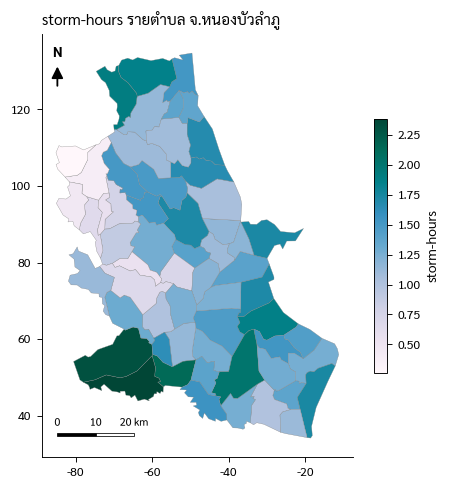

In [13]:
# @title เฉลยข้อ 2
prov = "หนองบัวลำภู"
tp = TAM[TAM["pro_th"] == prov]
display(tp.drop(columns="geometry").sort_values("storm_hours_mean", ascending=False).head(10).round(2))
fig, ax = plt.subplots(figsize=(5, 5))
M.plot_km(tp, ax, column="storm_hours_mean", cmap="PuBuGn", edgecolor="0.5", lw=0.2, legend=True,
          legend_kwds={"shrink": 0.6, "label": "storm-hours"})
ax.set_aspect("equal"); ax.set_title(f"storm-hours รายตำบล จ.{prov}", loc="left"); M.add_scalebar(ax, 20); M.add_north_arrow(ax)
plt.show()

**ข้อ 3** Moran's I ขึ้นกับนิยามเพื่อนบ้าน ลองใช้น้ำหนักแบบระยะ (อำเภอที่ centroid ห่างกันไม่เกิน 40 km) เทียบกับ queen contiguity ผลเปลี่ยนไปหรือไม่

In [14]:
# เขียนโค้ดของตนเองที่นี่

In [15]:
# @title เฉลยข้อ 3
from scipy import sparse
cen = np.c_[Ag.geometry.centroid.x, Ag.geometry.centroid.y]
dist = np.hypot(cen[:, None, 0] - cen[None, :, 0], cen[:, None, 1] - cen[None, :, 1]) / 1e3
Wd = ((dist > 0) & (dist <= 40)).astype(float)
rs = Wd.sum(1); rs[rs == 0] = 1
Wd = sparse.csr_matrix(Wd / rs[:, None])
print("queen:", A.morans_i(Ag[var].values, Wr)[:2], "| ระยะ 40 km:", A.morans_i(Ag[var].values, Wd)[:2])

queen: (0.5260079798709646, 0.001) | ระยะ 40 km: (0.463898176879777, 0.001)


## 8. คำถามชวนคิด
1. ความถี่ของ echo ไกลเรดาร์ถูกประเมินต่ำ (บท 02) hot spot ที่พบใกล้เรดาร์อาจเป็นผลของการวัดมากกว่าภูมิอากาศจริงหรือไม่ จะทดสอบอย่างไร
2. ข้อมูลเดือนเดียวพอสำหรับบอก "พื้นที่เสี่ยง" หรือไม่ ต้องใช้กี่ปีจึงเริ่มเชื่อถือได้
3. ถ้าจะให้ผลนี้ใช้วางแผนลดความเสี่ยงระดับตำบล ควรรวมข้อมูลอะไรเพิ่ม (จำนวนครัวเรือน ประเภทหลังคา พื้นที่เกษตร)

## 9. แนวทางต่อยอด
- รวมหลายปี/หลายเรดาร์ (ขอนแก่น อุบลฯ สกลนคร) เป็น mosaic เพื่อลดผลของระยะ
- ใช้ Local Moran (LISA) และปรับ p-value สำหรับการทดสอบซ้ำ (FDR)
- สร้างดัชนีความเสี่ยง = hazard (เรดาร์) × exposure (ประชากร/บ้าน) × vulnerability แล้วตรวจสอบกับรายงานหลายปี

**อ้างอิง:** Anselin (1995) *Geogr. Anal.* 27, 93–115; Ord & Getis (1995) *Geogr. Anal.* 27, 286–306; Silverman (1986) *Density Estimation*; Wilks (2019)